In [1]:
import time
import random
import requests
from urllib import robotparser
from bs4 import BeautifulSoup
import os
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

Настраиваю сессии для запросов.
User-Agent - представление парсера сайту. Указываю, что это учебный запрос.

In [2]:
HEADERS = {"User-Agent": "Mozilla/5.0 (educational for homework)"}
session = requests.Session()
session.headers.update(HEADERS)

Проверка robots.txt - файла, в котором сайт указывает, какие разделы разрешено обходить роботам.
Проверяю, что страницы хаба "Машинное обучение" можно парсить.
Результат True означает, что парсинг этих страниц разрешён.

In [3]:
rp = robotparser.RobotFileParser()
rp.set_url("https://habr.com/robots.txt")
rp.read()
test_url = "https://habr.com/ru/hubs/machine_learning/articles/page1/"
print("Можно парсить:", rp.can_fetch(HEADERS["User-Agent"], test_url))

Можно парсить: True


Функция "вежливого" запроса к сайту.
- time.sleep(random.uniform(1.0, 2.0)) - перед каждым запросом делает случайную паузу 1-2 секунды.
- wait = 60 * (attempt + 1) - если сайт отвечает 429 (слишком много запросов) или 503 (сервер перегружен), то ждёт 1, 2, затем 3 минуты и пробует снова (до 3 попыток).
- При сетевой ошибке ждёт 10 секунд и повторяет запрос.
- Возвращает ответ при успехе (код 200) или None, если страницу получить не удалось.

In [4]:
def polite_get(url, max_retries=3):
    for attempt in range(max_retries):
        time.sleep(random.uniform(1.0, 2.0))
        try:
            resp = session.get(url, timeout=15)
        except requests.RequestException as e:
            print(f"Ошибка: {e}")
            time.sleep(10)
            continue

        if resp.status_code == 200:
            return resp
        if resp.status_code in (429, 503):
            wait = 60 * (attempt + 1)
            print(f"{resp.status_code} ожидание {wait} сек")
            time.sleep(wait)
        else:
            print(f"Код {resp.status_code} для {url}")
            return None
    return None

Тестовый запрос - скачиваю первую страницу хаба "Машинное обучение".
Статус 200 означает, что страница успешно получена.

In [5]:
url = "https://habr.com/ru/hubs/machine_learning/articles/page1/"
resp = polite_get(url)
print("Статус:", resp.status_code if resp else None)

Статус: 200


Разбираю HTML страницы и ищу карточки статей  теги "article"

In [6]:
soup = BeautifulSoup(resp.text, "html.parser")
articles = soup.find_all("article")
print("Найдено:", len(articles))

Найдено: 20


Вывожу HTML код первой карточки, чтобы изучить её структуру и найти, где лежат:
- ссылка и заголовок - тег a с классом tm-title__link;
- дата публикации - атрибут datetime тега time;
- число просмотров - атрибут title тега с классом tm-icon-counter__value.

In [7]:
print(articles[0].prettify()[:3000])

<article class="tm-articles-list__item" data-navigatable="" id="1108160" tabindex="0">
 <div class="article-snippet" data-v-96702a45="">
  <!--[-->
  <!--]-->
  <div class="meta-container" data-v-96702a45="">
   <div class="meta" data-v-96702a45="">
    <span class="tm-user-info author" data-v-96702a45="">
     <a class="tm-user-info__userpic" href="/ru/users/iximy/">
      <!--[-->
      <div class="tm-entity-image">
       <!--[-->
       <img alt="" class="tm-entity-image__pic" height="24" loading="lazy" src="https://assets.habr.com/habr-web/release_2.360.4/client/img/avatars/161.png" width="24"/>
       <!--]-->
      </div>
      <!--]-->
     </a>
     <span class="tm-user-info__user tm-user-info__user_appearance-default">
      <a class="tm-user-info__username" href="/ru/users/iximy/">
       <!--[-->
       iximy
       <!--]-->
      </a>
      <!-- -->
      <!--[-->
      <a class="tm-article-datetime-published tm-article-datetime-published_link" data-v-96702a45="" href="/ru

Собираю список статей со всех страниц хаба

Функция parse_card извлекает из карточки id, ссылку, заголовок, дату публикации и просмотры.
Если какого-то элемента нет, карточка пропускается.
Цикл проходит по страницам page1, page2,... до MAX_PAGES и останавливается раньше, если страница недоступна или на ней нет статей. Дубликаты удаляются по id, результат сохраняется в habr_links.csv.

In [8]:
def parse_card(card):
    link = card.select_one("a.tm-title__link")
    time_tag = card.select_one("time")
    views = card.select_one(".reach-counter .tm-icon-counter__value")

    if link is None or time_tag is None or views is None:
        return None

    return {
        "id": card.get("id"),
        "url": "https://habr.com" + link["href"],
        "title": link.get_text(strip=True),
        "published": time_tag["datetime"],
        "views": int(views["title"]),
    }


HUB = "machine_learning"
MAX_PAGES = 100

cards_data = []
for page in range(1, MAX_PAGES + 1):
    url = f"https://habr.com/ru/hubs/{HUB}/articles/page{page}/"
    resp = polite_get(url)
    if resp is None:
        print(f"Страница {page} недоступна")
        break

    soup = BeautifulSoup(resp.text, "html.parser")
    cards = soup.find_all("article")
    if not cards:
        print(f"На странице {page} статей нет")
        break

    for card in cards:
        item = parse_card(card)
        if item:
            cards_data.append(item)

    print(f"Страница {page}: всего собрано {len(cards_data)}")

links_df = pd.DataFrame(cards_data).drop_duplicates(subset="id")
links_df.to_csv("habr_links.csv", index=False)
print(links_df.shape)
links_df.head()

Страница 1: всего собрано 20
Страница 2: всего собрано 40
Страница 3: всего собрано 60
Страница 4: всего собрано 80
Страница 5: всего собрано 100
Страница 6: всего собрано 120
Страница 7: всего собрано 140
Страница 8: всего собрано 160
Страница 9: всего собрано 180
Страница 10: всего собрано 200
Страница 11: всего собрано 220
Страница 12: всего собрано 240
Страница 13: всего собрано 260
Страница 14: всего собрано 280
Страница 15: всего собрано 300
Страница 16: всего собрано 320
Страница 17: всего собрано 340
Страница 18: всего собрано 360
Страница 19: всего собрано 380
Страница 20: всего собрано 400
Страница 21: всего собрано 420
Страница 22: всего собрано 440
Страница 23: всего собрано 460
Страница 24: всего собрано 480
Страница 25: всего собрано 500
Страница 26: всего собрано 520
Страница 27: всего собрано 540
Страница 28: всего собрано 560
Страница 29: всего собрано 580
Страница 30: всего собрано 600
Страница 31: всего собрано 620
Страница 32: всего собрано 640
Страница 33: всего со

,id,url,title,published,views
0,1108160,https://habr.com/ru/articles/1108160/,Цифровые двойники (Digital Twin) в инженерных ...,2026-11-16T18:09:11.000Z,3625
1,1108414,https://habr.com/ru/companies/itglobalcom/arti...,Корпоративная база знаний на базе ИИ,2026-11-16T14:49:16.000Z,5461
2,1103622,https://habr.com/ru/companies/timeweb/articles...,Запускаем языковую модель на ESP32 со скорость...,2026-11-16T14:05:05.000Z,8592
3,1108464,https://habr.com/ru/companies/bothub/articles/...,И так поймет: как сокращать промпты и считать ...,2026-11-16T13:32:12.000Z,5582
4,1107870,https://habr.com/ru/companies/syntx_ai/article...,Seedance 2.5: обзор нейросети и гайд по промпт...,2026-11-16T13:02:25.000Z,5232


Функция parse_article извлекает текст статьи со страницы статьи.
Текст лежит в блоке div с классом article-formatted-body.
Блоки кода (pre, code) удаляю, потому что для анализа текста они являются шумом.
Проверяю работу функции на одной статье, вывожу длину текста и его начало.

In [9]:
def parse_article(html):
    soup = BeautifulSoup(html, "html.parser")
    body = soup.select_one("div.article-formatted-body") or soup.select_one("#post-content-body")
    if body is None:
        return None

    for tag in body.find_all(["pre", "code"]):
        tag.decompose()

    return body.get_text(separator=" ", strip=True)


test_url = links_df.iloc[0]["url"]
resp = polite_get(test_url)
text = parse_article(resp.text)
print("Длина текста:", len(text) if text else None)
print(text[:500] if text else "Текст не найден")

Длина текста: 21460
В последние годы технология Digital Twin превратилась в один из главных трендов промышленной автоматизации. Крупные вендоры - Siemens, Schneider, Aveva, и десятки других предлагают платформы, в которых «двойник» обещает предсказывать отказы, оптимизировать режимы, экономить миллионы. Аналитики Gartner и MarketsandMarkets оценивают рынок в десятки миллиардов долларов к концу десятилетия. На практике картина скромнее. Многие компании ограничиваются цифровыми двойниками отдельных технологических пр


Скачиваю полные тексты всех статей с сохранением прогресса.
- Каждая статья сразу дописывается в файл habr_texts.csv (f.flush() записывает на диск).
- При повторном запуске код читает файл, пропускает уже скачанные статьи и продолжает с места остановки для парсинга с перерывами.
- Каждые 50 статей выводится прогресс.

In [10]:
OUT_FILE = "habr_texts.csv"

done_ids = set()
if os.path.exists(OUT_FILE):
    done_ids = set(pd.read_csv(OUT_FILE, usecols=["id"])["id"].astype(str))
print("Скачано:", len(done_ids))

todo = links_df[~links_df["id"].astype(str).isin(done_ids)]
print("Осталось скачать:", len(todo))

write_header = not os.path.exists(OUT_FILE)
with open(OUT_FILE, "a", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["id", "text"])
    if write_header:
        writer.writeheader()

    for i, row in enumerate(todo.itertuples(), 1):
        resp = polite_get(row.url)
        if resp is None:
            continue
        text = parse_article(resp.text)
        if text:
            writer.writerow({"id": row.id, "text": text})
            f.flush()
        if i % 50 == 0:
            print(f"{i}/{len(todo)}")

Скачано: 0
Осталось скачать: 2000
50/2000
100/2000
150/2000
200/2000
250/2000
300/2000
350/2000
400/2000
450/2000
500/2000
550/2000
600/2000
650/2000
700/2000
750/2000
800/2000
850/2000
900/2000
950/2000
1000/2000
1050/2000
1100/2000
1150/2000
1200/2000
1250/2000
1300/2000
1350/2000
1400/2000
1450/2000
1500/2000
1550/2000
1600/2000
1650/2000
1700/2000
1750/2000
1800/2000
1850/2000
1900/2000
1950/2000
2000/2000


Загружаю собранные данные из CSV-файлов и проверяю результат. Размер таблицы с текстами и статистику длины текстов (минимум, среднее и  максимум), чтобы убедиться, что пустых или слишком коротких текстов нет.

In [11]:
links_df = pd.read_csv("habr_links.csv")
texts_df = pd.read_csv("habr_texts.csv")

In [12]:
print("Ссылок:", links_df.shape)
print("Текстов:", texts_df.shape)
print(texts_df["text"].str.len().describe())

Ссылок: (2000, 5)
Текстов: (2000, 2)
count      2000.0000
mean      11047.0060
std       10977.6816
min          36.0000
25%        3047.7500
50%        8629.5000
75%       15455.0000
max      123823.0000
Name: text, dtype: float64


Объединяю таблицы по id статьи. К каждому тексту добавляю дату публикации и число просмотров.
Удаляю слишком короткие тексты (меньше 300 символов).

In [13]:
df = links_df.merge(texts_df, on="id", how="inner")
print("После объединения:", df.shape)

После объединения: (2000, 6)


In [14]:
df = df[df["text"].str.len() >= 300].reset_index(drop=True)
print("После удаления коротких текстов:", df.shape)

После удаления коротких текстов: (1984, 6)


Считаю целевую переменную - среднее число просмотров в день.
Дни считаю от даты публикации до момента сбора данных (время последнего изменения файла habr_links.csv).
Удаляю статьи < 3 дней, так как в первые дни просмотры растут очень быстро, и среднее в день для них получается завышенным и нестабильным.

In [15]:
scrape_time = pd.Timestamp(os.path.getmtime("habr_links.csv"), unit="s", tz="UTC")
print("Момент сбора данных:", scrape_time)

Момент сбора данных: 2026-11-16 20:22:34.167943001+00:00


In [16]:
df["published"] = pd.to_datetime(df["published"], utc=True)
df["days"] = (scrape_time - df["published"]).dt.total_seconds() / 86400

df = df[df["days"] >= 3].reset_index(drop=True)
df["views_per_day"] = df["views"] / df["days"]

In [17]:
print("Статей осталось:", len(df))
print("Период публикаций:", df["published"].min().date(), "—", df["published"].max().date())
print(df["views_per_day"].describe())

Статей осталось: 1952
Период публикаций: 2026-07-14 — 2026-11-13
count     1952.000000
mean       346.897154
std        817.949515
min         34.270119
25%         91.928323
50%        140.790152
75%        269.646143
max      17402.227374
Name: views_per_day, dtype: float64


Смотрю на распределение целевой переменной.
У просмотров в день длинный правый хвост, у большинства статей мало просмотров, у единиц очень много. Линейная регрессия чувствительна к таким выбросам, поэтому беру логарифм log(1 + просмотры в день).

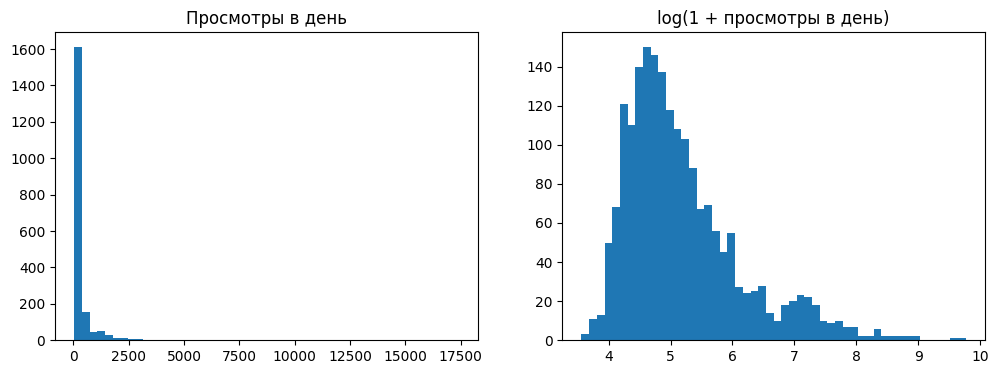

In [18]:
df["target"] = np.log1p(df["views_per_day"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["views_per_day"], bins=50)
axes[0].set_title("Просмотры в день")
axes[1].hist(df["target"], bins=50)
axes[1].set_title("log(1 + просмотры в день)")
plt.show()

In [19]:
df.to_csv("habr_dataset.csv", index=False)

Разбиваю данные на обучающую (80%) и тестовую (20%) выборки.
random_state фиксирую, чтобы разбиение было воспроизводимым при каждом запуске.
Тестовая выборка не используется при обучении и подборе параметров, только для финальной оценки качества.

In [20]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["text"], df["target"], test_size=0.2, random_state=42
)
print("Train:", len(X_train_text), "Test:", len(X_test_text))

Train: 1561 Test: 391


Составляю список стоп-слов (частых служебных слов: предлоги, союзы, местоимения), которые не несут смысла для предсказания просмотров.
Беру русские стоп-слова из библиотеки nltk и добавляю английские из sklearn, потому что в статьях про ML много английских слов.

In [21]:
nltk.download("stopwords")
stop_words = list(set(stopwords.words("russian")) | set(ENGLISH_STOP_WORDS))
print("Стоп-слов:", len(stop_words))

Стоп-слов: 469


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


TF-IDF преобразование текстов. Параметры:
- ngram_range=(1, 2). Используются отдельные слова и биграммы (пары соседних слов);
- stop_words. Убираются стоп-слова;
- min_df=5. Убираются слишком редкие слова (встречаются меньше чем в 5 статьях);
- max_df=0.5. Убираются слишком частые слова (встречаются больше чем в половине статей);
- norm=None. Отключается l2-нормировка векторов, которая включена по умолчанию;
- sublinear_tf=True. Берется логарифм частоты слова (1 + log(tf)), чтобы длинные статьи с многократными повторами не получали огромные значения признаков;
- token_pattern. Остаются только слова из букв длиной от 2 символов, без чисел.
Векторизатор обучаю только на train, а test только преобразую, чтобы информация из тестовой выборки при обучении не попала в трейн.

In [22]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    stop_words=stop_words,
    min_df=5,
    max_df=0.5,
    norm=None,
    sublinear_tf=True,
    token_pattern=r"(?u)\b[^\W\d_]{2,}\b",
)

X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

In [23]:
print("Размер train:", X_train.shape)
print("Размер test:", X_test.shape)
print("Примеры признаков:", vectorizer.get_feature_names_out()[:20])

Размер train: (1561, 44844)
Размер test: (391, 44844)
Примеры признаков: ['aa' 'aa omniscience' 'abc' 'ablation' 'abliterated' 'abliteration' 'abs'
 'acc' 'accept' 'acceptance' 'access' 'account' 'accuracy' 'acl' 'acm'
 'acp' 'act' 'action' 'actions' 'activation']


Строю линейную регрессию с L2-регуляризацией (Ridge). Признаков больше, чем наблюдений, поэтому без регуляризации модель переобучится.
Параметр регуляризации alpha подбираю по сетке значений от 0.1 до 100 000 с помощью кросс-валидации на 5 фолдов (GridSearchCV) только на обучающей выборке.
Метрика для подбора RMSE (корень из средней квадратичной ошибки).

In [24]:
alphas = np.logspace(-1, 5, 25)

grid = GridSearchCV(
    Ridge(),
    param_grid={"alpha": alphas},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
grid.fit(X_train, y_train)

best_alpha = grid.best_params_["alpha"]

In [25]:
print("Лучший alpha:", best_alpha)
print("RMSE на кросс-валидации:", -grid.best_score_)

Лучший alpha: 5623.413251903491
RMSE на кросс-валидации: 0.8659002686082564


График зависимости ошибки на кросс-валидации от alpha.
При маленьком alpha модель переобучается (слабый штраф), при очень большом недообучается (коэффициенты сжимаются почти до нуля). Оптимум находится между этими крайностями.

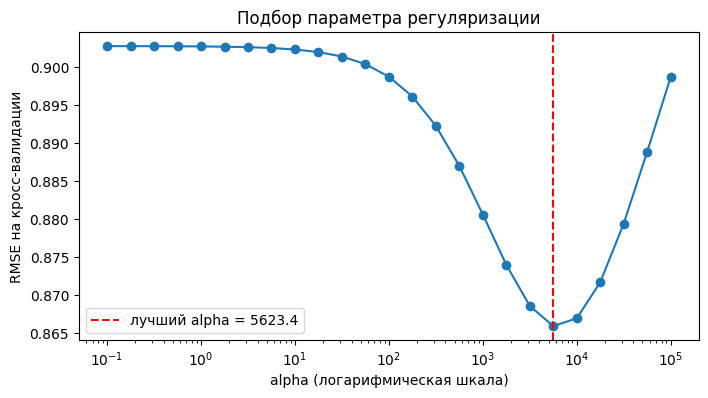

In [26]:
cv_rmse = -grid.cv_results_["mean_test_score"]

plt.figure(figsize=(8, 4))
plt.semilogx(alphas, cv_rmse, marker="o")
plt.axvline(best_alpha, color="red", linestyle="--", label=f"лучший alpha = {best_alpha:.1f}")
plt.xlabel("alpha (логарифмическая шкала)")
plt.ylabel("RMSE на кросс-валидации")
plt.title("Подбор параметра регуляризации")
plt.legend()
plt.show()

Оцениваю качество лучшей модели на тестовой выборке. Метрики регрессии:
- R^2 - доля разброса целевой переменной, которую объясняет модель (1 - идеально, 0 - не лучше среднего);
- RMSE и MAE - средняя ошибка в единицах log(1 + просмотры в день);
- MAE в просмотрах - ошибка после обратного преобразования (expm1).
Для сравнения считаю baseline модель, которая для всех статей предсказывает среднее значение train. Хорошая модель должна быть лучше baseline.

In [27]:
model = grid.best_estimator_
y_pred = model.predict(X_test)
y_base = np.full_like(y_test, y_train.mean(), dtype=float)

def report(name, y_true, y_hat):
    print(f"{name}:")
    print(f"R^2 = {r2_score(y_true, y_hat):.3f}")
    print(f"RMSE = {mean_squared_error(y_true, y_hat) ** 0.5:.3f}")
    print(f"MAE = {mean_absolute_error(y_true, y_hat):.3f}")
    print(f"MAE в просмотрах/день = {mean_absolute_error(np.expm1(y_true), np.expm1(y_hat)):.1f}")

report("Ridge", y_test, y_pred)
report("Baseline (среднее)", y_test, y_base)
print("R^2 на train:", round(r2_score(y_train, model.predict(X_train)), 3))

Ridge:
R^2 = 0.165
RMSE = 0.872
MAE = 0.658
MAE в просмотрах/день = 274.4
Baseline (среднее):
R^2 = -0.000
RMSE = 0.954
MAE = 0.730
MAE в просмотрах/день = 282.7
R^2 на train: 0.856


График "предсказание против реального значения" на тестовой выборке. Чем ближе точки к красной диагонали, тем точнее модель.

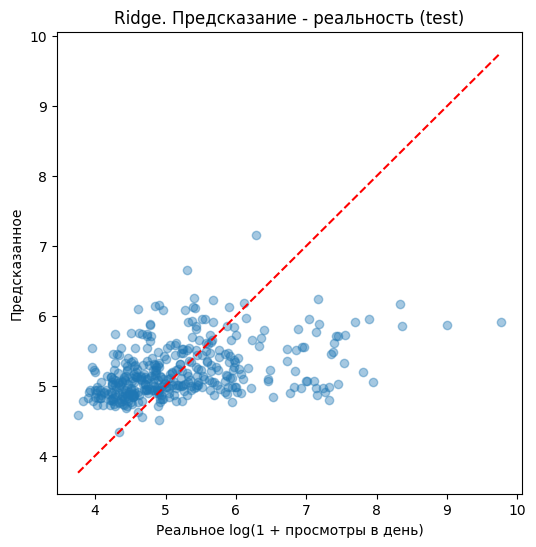

In [28]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.4)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, color="red", linestyle="--")
plt.xlabel("Реальное log(1 + просмотры в день)")
plt.ylabel("Предсказанное")
plt.title("Ridge. Предсказание - реальность (test)")
plt.show()

Вывод по качеству модели:
- Лучший параметр регуляризации alpha ~ 5623, он находится внутри сетки, оптимум найден.
- На тестовой выборке Ridge даёт R^2 = 0.165, а baseline R^2 ~ 0. Модель лучше baseline и объясняет около 17% разброса популярности статей только по их тексту.
- RMSE снизился с 0.954 (baseline) до 0.872, MAE с 0.730 до 0.658.
- R^2 на train (0.856) заметно выше, чем на test (0.165). Модель частично переобучается, так как признаков (44 844) намного больше, чем наблюдений (1561). Регуляризация сдерживает это переобучение.
- Невысокий R^2 ожидаем, так как популярность статьи зависит не только от текста, но и от случайных факторов.

Извлекаю коэффициенты регрессии для каждого слова/биграммы.
1. Положительный коэффициент. Чем чаще слово встречается в статье, тем больше предсказанное число просмотров в день.

2. Отрицательный коэффициент. Слово связано с меньшими просмотрами.
Беру 25 слов с наибольшими положительными и 25 с наименьшими отрицательными коэффициентами.

In [29]:
feature_names = vectorizer.get_feature_names_out()
coefs = pd.DataFrame({"word": feature_names, "coef": model.coef_})

top_pos = coefs.nlargest(25, "coef")
top_neg = coefs.nsmallest(25, "coef")
top50 = pd.concat([top_pos, top_neg]).sort_values("coef")

In [30]:
print("Повышают просмотры:\n", top_pos["word"].tolist())
print("Понижают просмотры:\n", top_neg["word"].tolist())

Повышают просмотры:
 ['ноября', 'strata', 'гб', 'flash', 'uncensored', 'тыс', 'код', 'сообщение', 'аккаунтов', 'обучающей', 'ноября года', 'инженеров', 'anthropic', 'astra', 'примечательно', 'стоит', 'кодом', 'опыта', 'промпт', 'копии', 'claude', 'согласно', 'права', 'проверить', 'примеров']
Понижают просмотры:
 ['августа', 'инструмент', 'представлен', 'июля', 'представлен открытый', 'аудит', 'открытый проект', 'пояснили', 'новый', 'отчёт', 'сервис', 'пользователь', 'яндекс', 'собой', 'цены', 'внутри', 'иметь', 'материал', 'skills', 'любой', 'сентября', 'контекста', 'gemini flash', 'открытый', 'уровень']


Визуализация топ-50 коэффициентов. Зелёным слова, связанные с ростом просмотров, красным - со снижением.

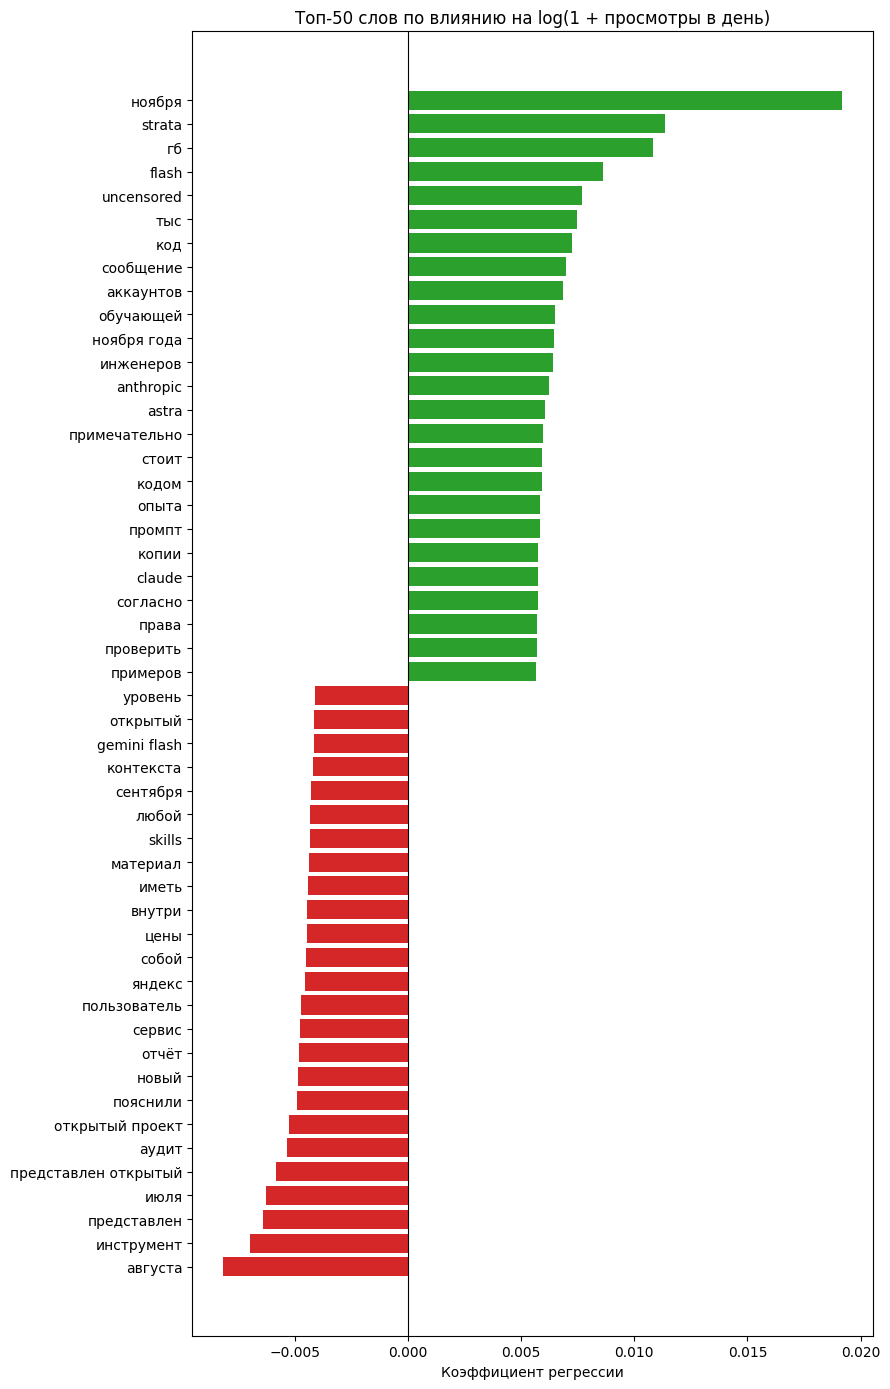

In [31]:
colors = ["tab:green" if c > 0 else "tab:red" for c in top50["coef"]]

plt.figure(figsize=(9, 14))
plt.barh(top50["word"], top50["coef"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Коэффициент регрессии")
plt.title("Топ-50 слов по влиянию на log(1 + просмотры в день)")
plt.tight_layout()
plt.show()

# Интерпретация коэффициентов

1. Время публикации. Среди самых сильных признаков названия месяцев: "ноября", "ноября года" повышают прогноз, "июля", "августа", "сентября" понижают. Модель через текст узнает возраст статьи. Основная часть просмотров приходит в первые дни после публикации, поэтому у старых статей среднее число просмотров в день ниже.

2. Свежие и обсуждаемые модели. Положительные коэффициенты у названий новых моделей и компаний: "strata", "astra", "flash", "anthropic", "claude". Статьи о самых свежих релизах читают больше. "gemini flash" в отрицательных, к моменту сбора данных интерес к нему спал. Также в "плюсе" статьи о моделях без ограничений привлекают повышенный интерес.

3. Практические статьи. В "плюсе" слова, связанные с практической работой: "код", "кодом", "гб", "промпт", "проверить", "примеров", "опыта", "инженеров".

4. Аккаунты и права. В плюсе: "аккаунтов", "права", "копии", "сообщение". Предположительно, это статьи о безопасности и ИИ (актуальные темы).

5. Новостные тексты. Отрицательные коэффициенты у слов из коротких новостей и анонсов продуктов: "представлен", "представлен открытый", "открытый проект", "пояснили", "новый", "отчёт", "сервис", "инструмент", "цены".

# Итог
Модель на основе TF-IDF и Ridge-регрессии объясняет около 17% разброса популярности статей и работает лучше baseline. По коэффициентам видно, что больше просмотров набирают свежие статьи о новых моделях и практические материалы с кодом, а меньше новостные пересказы и корпоративные тексты. Ограничение модели: часть её знаний - это возраст статьи, а не содержание текста. Чтобы это исправить, можно добавить названия месяцев в стоп-слова или брать статьи одного возраста.

# Эксперимент.
## Убираю месяцы.
Добавляю названия месяцев в стоп-слова и заново строю TF-IDF и Ridge с подбором alpha.
Цель - проверить, насколько качество модели зависело от упоминания дат, и получить коэффициенты, которые лучше отражают содержание статей.

In [32]:
month_words = [
    "январь", "января", "январе", "январю", "январём",
    "февраль", "февраля", "феврале", "февралю", "февралём",
    "март", "марта", "марте", "марту", "мартом",
    "апрель", "апреля", "апреле", "апрелю", "апрелем",
    "май", "мая", "мае", "маю", "маем",
    "июнь", "июня", "июне", "июню", "июнем",
    "июль", "июля", "июле", "июлю", "июлем",
    "август", "августа", "августе", "августу", "августом",
    "сентябрь", "сентября", "сентябре", "сентябрю", "сентябрём",
    "октябрь", "октября", "октябре", "октябрю", "октябрём",
    "ноябрь", "ноября", "ноябре", "ноябрю", "ноябрём",
    "декабрь", "декабря", "декабре", "декабрю", "декабрём",
    "january", "february", "march", "april", "may", "june", "july",
    "august", "september", "october", "november", "december",
]

stop_words_2 = list(set(stop_words) | set(month_words))
print("Стоп-слов:", len(stop_words_2))

Стоп-слов: 540


Заново строю TF-IDF с теми же параметрами, но с расширенным списком стоп-слов, и подбираю alpha для Ridge кросс-валидацией.

In [33]:
vectorizer_2 = TfidfVectorizer(
    ngram_range=(1, 2),
    stop_words=stop_words_2,
    min_df=5,
    max_df=0.5,
    norm=None,
    sublinear_tf=True,
    token_pattern=r"(?u)\b[^\W\d_]{2,}\b",
)
X_train_2 = vectorizer_2.fit_transform(X_train_text)
X_test_2 = vectorizer_2.transform(X_test_text)

grid_2 = GridSearchCV(
    Ridge(),
    param_grid={"alpha": alphas},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
grid_2.fit(X_train_2, y_train)
model_2 = grid_2.best_estimator_

In [34]:
print("Признаков:", X_train_2.shape[1])
print("Лучший alpha:", grid_2.best_params_["alpha"])

Признаков: 44771
Лучший alpha: 5623.413251903491


In [35]:
report("Ridge без месяцев", y_test, model_2.predict(X_test_2))
report("Ridge исходный", y_test, y_pred)

Ridge без месяцев:
R^2 = 0.150
RMSE = 0.880
MAE = 0.664
MAE в просмотрах/день = 275.9
Ridge исходный:
R^2 = 0.165
RMSE = 0.872
MAE = 0.658
MAE в просмотрах/день = 274.4


Топ-50 коэффициентов новой модели (без названий месяцев).

In [36]:
coefs_2 = pd.DataFrame({"word": vectorizer_2.get_feature_names_out(), "coef": model_2.coef_})
top_pos_2 = coefs_2.nlargest(25, "coef")
top_neg_2 = coefs_2.nsmallest(25, "coef")
top50_2 = pd.concat([top_pos_2, top_neg_2]).sort_values("coef")

In [37]:
print("Повышают просмотры:\n", top_pos_2["word"].tolist())
print("Понижают просмотры:\n", top_neg_2["word"].tolist())

Повышают просмотры:
 ['strata', 'гб', 'flash', 'uncensored', 'тыс', 'код', 'сообщение', 'аккаунтов', 'обучающей', 'инженеров', 'anthropic', 'astra', 'стоит', 'примечательно', 'кодом', 'промпт', 'claude', 'опыта', 'согласно', 'копии', 'открытых', 'хотя', 'словам', 'очистки', 'tv']
Понижают просмотры:
 ['инструмент', 'представлен', 'представлен открытый', 'аудит', 'открытый проект', 'пояснили', 'отчёт', 'новый', 'сервис', 'пользователь', 'яндекс', 'цены', 'собой', 'внутри', 'материал', 'иметь', 'skills', 'любой', 'открытый', 'контекста', 'рынок', 'gemini flash', 'уровень', 'взгляд', 'поведения']


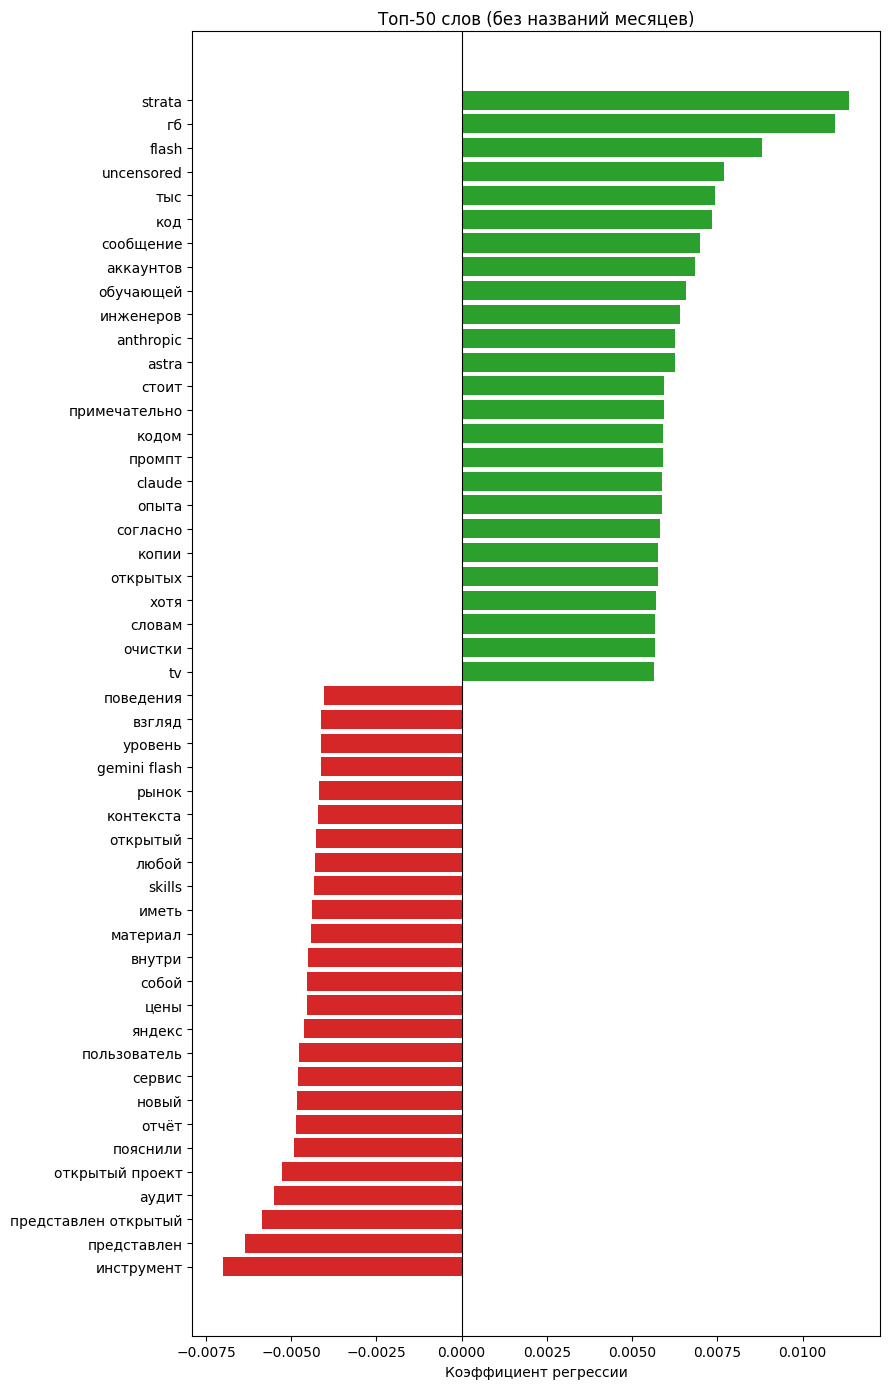

In [38]:
colors = ["tab:green" if c > 0 else "tab:red" for c in top50_2["coef"]]
plt.figure(figsize=(9, 14))
plt.barh(top50_2["word"], top50_2["coef"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Коэффициент регрессии")
plt.title("Топ-50 слов (без названий месяцев)")
plt.tight_layout()
plt.show()

# Вывод по эксперименту.

- После удаления названий месяцев R^2 на тесте снизился незначительно: с 0.165 до 0.150 (RMSE с 0.872 до 0.880). Лучший alpha не изменился (~5623).
- Упоминания дат давали лишь небольшую часть качества модели, основную предсказательную силу дают слова, связанные с содержанием статей.
- Остальной топ коэффициентов почти не изменился. В "плюсе" по-прежнему свежие модели и компании, в "минусе" новостные заметки.